<a href="https://colab.research.google.com/github/khanggLT/baitapA2/blob/main/baitapA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# khai báo công cụ AI
# công cụ đã dùng: Claude (Anthropic)
# phần AI hỗ trợ: soạn bản nháp đầu tiên của notebook này, của báo cáo word và của kịch bản báo cáo miệng
# phần sinh viên làm: tải dữ liệu, chạy lại toàn bộ notebook, kiểm tra số liệu, chỉnh sửa và giải thích được từng dòng code

# bài tập lớn A2, đề tài A2-04: phân tích kết quả học tập sinh viên
# nguồn dữ liệu: bộ UCI Student Performance (P. Cortez và A. Silva, 2008), bản đăng trên Kaggle: uciml/student-alcohol-consumption
# file sử dụng: student-mat.csv (môn toán, 395 học sinh, 33 cột)
# giấy phép: bản đăng lại của bộ dữ liệu này ghi CC0 1.0, cần đối chiếu lại mục license trên trang Kaggle trước khi nộp
# trích dẫn: P. Cortez and A. Silva. Using Data Mining to Predict Secondary School Student Performance. FUBUTEC 2008, pp. 5-12

# đạo đức dữ liệu
# dùng dữ liệu công khai có sẵn nên không tự thu thập phiếu khảo sát, vì vậy không có phiếu đồng ý
# không thu thập thêm thông tin định danh nào, phần làm sạch bên dưới có kiểm tra bộ dữ liệu không có cột tên hay mã học sinh
# tài liệu mô tả bộ dữ liệu cho biết có thể nhận ra cùng một học sinh ở hai file (toán và tiếng Bồ Đào Nha) bằng cách ghép các thuộc tính giống nhau
# nên báo cáo không đăng bảng dữ liệu từng dòng, chỉ đăng kết quả tổng hợp theo nhóm

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# thư viện
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

In [ ]:
# đọc dữ liệu
# tải student-mat.csv từ kaggle và để cùng thư mục với notebook này
# sep=None để pandas tự đoán dấu phân cách (dấu phẩy hoặc chấm phẩy)
duong_dan = 'student-mat.csv'
df = pd.read_csv(duong_dan, sep=None, engine='python')
print(df.shape)
print(df.head())

(395, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  reason guardian  traveltime  studytime  failures schoolsup famsup paid activities nursery higher internet romantic  famrel  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  course   mother           2          2         0       yes     no   no         no     yes    yes       no       no       4   
1     GP   F   17       U     GT3       T     1     1  at_home     other  course   father           1          2         0        no    yes   no         no      no    yes      yes       no       5   
2     GP   F   15       U     LE3       T     1     1  at_home     other   other   mother           1          2         3       yes     no  yes         no     yes    yes      yes       no       4   
3     GP   F   15       U     GT3       T     4     2   health  services    home   mother           1          3         0        no    yes  yes        yes     yes    yes      yes      yes  

In [ ]:
# làm sạch bước 1: chuẩn hóa tên cột và kiểu dữ liệu
# lý do: tên cột viết thường cho dễ gõ, cột số phải đúng kiểu số thì mới tính thống kê được
# cột chữ bị thừa khoảng trắng thì cùng một giá trị bị tách thành hai nhóm nên cần cắt khoảng trắng
df.columns = df.columns.str.strip().str.lower()

cot_so = ['age', 'medu', 'fedu', 'traveltime', 'studytime', 'failures', 'famrel',
          'freetime', 'goout', 'dalc', 'walc', 'health', 'absences', 'g1', 'g2', 'g3']
cot_chu = [c for c in df.columns if c not in cot_so]

for cot in cot_chu:
    df[cot] = df[cot].str.strip()

# ép về kiểu số, giá trị nào không đổi được sẽ thành thiếu và xử lý ở bước 2
for cot in cot_so:
    df[cot] = pd.to_numeric(df[cot], errors='coerce')

print(df.dtypes)

school        object
sex           object
age            int64
address       object
famsize       object
pstatus       object
medu           int64
fedu           int64
mjob          object
fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
dalc           int64
walc           int64
health         int64
absences       int64
g1             int64
g2             int64
g3             int64
dtype: object


In [ ]:
# làm sạch bước 2: giá trị thiếu
# cách xử lý: cột số điền bằng trung vị (không bị kéo lệch bởi giá trị lớn bất thường)
# cột chữ điền bằng giá trị xuất hiện nhiều nhất
so_thieu = df.isna().sum()
print('tổng số ô thiếu:', so_thieu.sum())
print(so_thieu[so_thieu > 0])

for cot in df.columns:
    if df[cot].isna().sum() > 0:
        if cot in cot_so:
            df[cot] = df[cot].fillna(df[cot].median())
        else:
            df[cot] = df[cot].fillna(df[cot].mode()[0])

print('sau khi xử lý, tổng số ô thiếu:', df.isna().sum().sum())

tổng số ô thiếu: 0
Series([], dtype: int64)
sau khi xử lý, tổng số ô thiếu: 0


In [ ]:
# làm sạch bước 3: giá trị sai miền (sai kiểu hoặc không hợp lý)
# lý do: điểm phải nằm trong thang 0 đến 20, tuổi trong 15 đến 22, các biến mức độ trong khoảng của bảng mô tả
# dòng nào vượt miền giá trị thì loại, vì không biết giá trị đúng là bao nhiêu
gioi_han = {
    'age': (15, 22), 'medu': (0, 4), 'fedu': (0, 4), 'traveltime': (1, 4),
    'studytime': (1, 4), 'failures': (0, 4), 'famrel': (1, 5), 'freetime': (1, 5),
    'goout': (1, 5), 'dalc': (1, 5), 'walc': (1, 5), 'health': (1, 5),
    'absences': (0, 100), 'g1': (0, 20), 'g2': (0, 20), 'g3': (0, 20)
}

dong_sai = pd.Series(False, index=df.index)
for cot, (thap, cao) in gioi_han.items():
    sai = (df[cot] < thap) | (df[cot] > cao)
    if sai.sum() > 0:
        print(cot, 'có', sai.sum(), 'dòng sai miền')
    dong_sai = dong_sai | sai

print('số dòng sai miền giá trị:', dong_sai.sum())
df = df[~dong_sai]
print('số dòng còn lại:', len(df))

số dòng sai miền giá trị: 0
số dòng còn lại: 395


In [ ]:
# làm sạch bước 4: dòng trùng lặp
# lý do: một học sinh bị đếm hai lần sẽ làm lệch thống kê
print('số dòng trùng:', df.duplicated().sum())
df = df.drop_duplicates()
print('số dòng còn lại:', len(df))

số dòng trùng: 0
số dòng còn lại: 395


In [ ]:
# làm sạch bước 5: ngoại lai
# dùng quy tắc iqr cho số buổi vắng (absences)
q1 = df['absences'].quantile(0.25)
q3 = df['absences'].quantile(0.75)
iqr = q3 - q1
can_tren = q3 + 1.5 * iqr
print('ngưỡng ngoại lai của số buổi vắng:', can_tren)
print('số học sinh vượt ngưỡng:', (df['absences'] > can_tren).sum())
print('số buổi vắng lớn nhất:', df['absences'].max())

# quyết định: giữ lại các giá trị này
# lý do: đây là số buổi vắng có thật (không vượt 100), xóa đi là mất đúng nhóm học sinh vắng nhiều cần quan tâm
# thay vào đó dùng biểu đồ hộp và trung vị để mô tả, ít bị ảnh hưởng bởi ngoại lai

# điểm g3 bằng 0 cũng không coi là lỗi nhập liệu vì nằm trong thang 0 đến 20
# giữ lại và phân tích riêng như một nhóm
print('số học sinh có g3 bằng 0:', (df['g3'] == 0).sum())

# kiểm tra định danh: bộ dữ liệu không được có cột tên hay mã học sinh
cot_dinh_danh = [c for c in df.columns if c in ['name', 'ten', 'id', 'mssv', 'email', 'phone']]
print('cột định danh trực tiếp:', cot_dinh_danh)

df = df.reset_index(drop=True)
print('kích thước sau khi làm sạch:', df.shape)

ngưỡng ngoại lai của số buổi vắng: 20.0
số học sinh vượt ngưỡng: 15
số buổi vắng lớn nhất: 75
số học sinh có g3 bằng 0: 38
cột định danh trực tiếp: []
kích thước sau khi làm sạch: (395, 33)


In [ ]:
# khám phá dữ liệu: thống kê mô tả
# g1, g2, g3 là điểm ba giai đoạn trong năm (thang 0 đến 20), g3 là điểm cuối
# ghép với đề: điểm học phần trước là g1, g2 và failures, thời gian học là studytime, số buổi vắng là absences
cot_chinh = ['age', 'studytime', 'failures', 'absences', 'g1', 'g2', 'g3']
print(df[cot_chinh].describe().round(2))

# phân bố một số biến phân loại
for cot in ['school', 'sex', 'address', 'internet', 'paid']:
    print(df[cot].value_counts())

# nhóm nguy cơ: g3 dưới 10 (giả định ngưỡng đạt là 10 trên thang 20)
# điểm giữa kỳ: trung bình của g1 và g2, là hai điểm có trước điểm cuối
df['nguy_co'] = (df['g3'] < 10).astype(int)
df['tb_giua_ky'] = (df['g1'] + df['g2']) / 2
print(df['nguy_co'].value_counts())

          age  studytime  failures  absences      g1      g2      g3
count  395.00     395.00    395.00    395.00  395.00  395.00  395.00
mean    16.70       2.04      0.33      5.71   10.91   10.71   10.42
std      1.28       0.84      0.74      8.00    3.32    3.76    4.58
min     15.00       1.00      0.00      0.00    3.00    0.00    0.00
25%     16.00       1.00      0.00      0.00    8.00    9.00    8.00
50%     17.00       2.00      0.00      4.00   11.00   11.00   11.00
75%     18.00       2.00      0.00      8.00   13.00   13.00   14.00
max     22.00       4.00      3.00     75.00   19.00   19.00   20.00
school
GP    349
MS     46
Name: count, dtype: int64
sex
F    208
M    187
Name: count, dtype: int64
address
U    307
R     88
Name: count, dtype: int64
internet
yes    329
no      66
Name: count, dtype: int64
paid
no     214
yes    181
Name: count, dtype: int64
nguy_co
0    265
1    130
Name: count, dtype: int64


In [ ]:
# khám phá dữ liệu: quan hệ giữa các biến
# tương quan pearson của từng biến số với g3 (từ -1 đến 1)
cot_so_eda = ['age', 'medu', 'fedu', 'traveltime', 'studytime', 'failures', 'famrel',
              'freetime', 'goout', 'dalc', 'walc', 'health', 'absences', 'g1', 'g2']
tuong_quan = df[cot_so_eda + ['g3']].corr()['g3'].drop('g3').sort_values()
print(tuong_quan.round(2))

# so sánh tương quan của số buổi vắng khi có và không có nhóm g3 bằng 0
khac_0 = df[df['g3'] > 0]
print('tương quan absences và g3 (tất cả):', round(df['absences'].corr(df['g3']), 2))
print('tương quan absences và g3 (bỏ nhóm g3 bằng 0):', round(khac_0['absences'].corr(khac_0['g3']), 2))

failures     -0.36
age          -0.16
goout        -0.13
traveltime   -0.12
health       -0.06
dalc         -0.05
walc         -0.05
freetime      0.01
absences      0.03
famrel        0.05
studytime     0.10
fedu          0.15
medu          0.22
g1            0.80
g2            0.90
Name: g3, dtype: float64
tương quan absences và g3 (tất cả): 0.03
tương quan absences và g3 (bỏ nhóm g3 bằng 0): -0.21


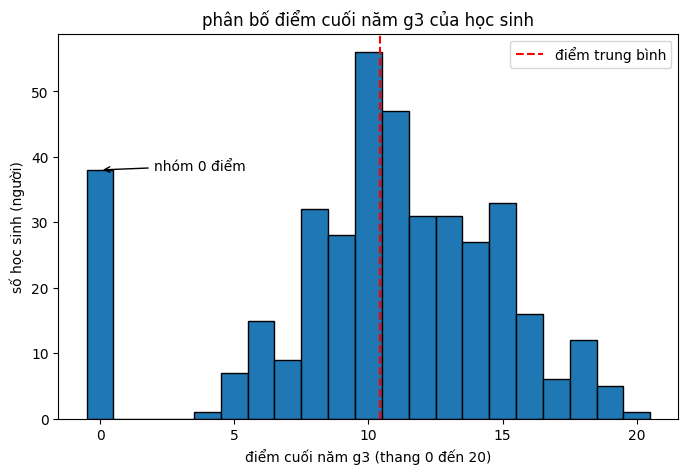

diễn giải biểu đồ 1: phần lớn học sinh tập trung quanh mức 11.0 điểm, có 38 học sinh ( 9.6 % ) bị 0 điểm nằm tách ra hẳn khỏi phần còn lại, điểm thấp nhất của phần còn lại là 4


In [ ]:
# biểu đồ 1: phân bố điểm cuối g3 (câu hỏi 1)
so_0 = (df['g3'] == 0).sum()
plt.figure(figsize=(8, 5))
plt.hist(df['g3'], bins=np.arange(-0.5, 21.5, 1), edgecolor='black')
plt.axvline(df['g3'].mean(), color='red', linestyle='--', label='điểm trung bình')
plt.annotate('nhóm 0 điểm', xy=(0, so_0), xytext=(2, so_0), arrowprops=dict(arrowstyle='->'))
plt.title('phân bố điểm cuối năm g3 của học sinh')
plt.xlabel('điểm cuối năm g3 (thang 0 đến 20)')
plt.ylabel('số học sinh (người)')
plt.legend()
plt.savefig('hinh1.png', dpi=150, bbox_inches='tight')
plt.show()

# diễn giải bằng ngôn ngữ nghiệp vụ
print('diễn giải biểu đồ 1: phần lớn học sinh tập trung quanh mức', round(df['g3'].median(), 1),
      'điểm, có', so_0, 'học sinh (', round(so_0 / len(df) * 100, 1),
      '% ) bị 0 điểm nằm tách ra hẳn khỏi phần còn lại, điểm thấp nhất của phần còn lại là',
      df[df['g3'] > 0]['g3'].min())

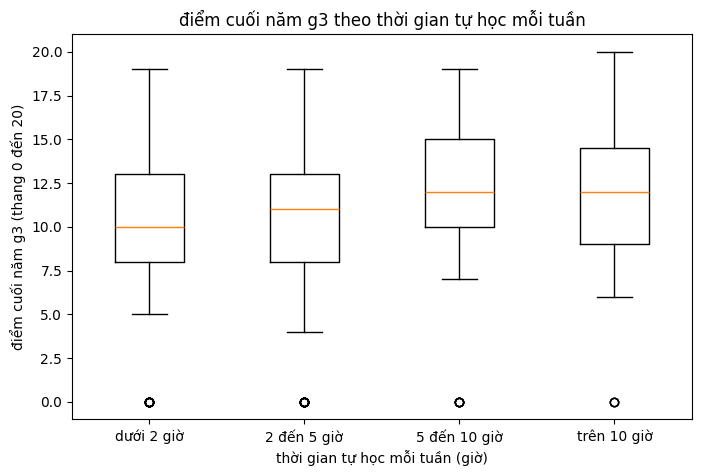

diễn giải biểu đồ 2: điểm trung vị theo bốn mức thời gian học lần lượt là
studytime
1    10.0
2    11.0
3    12.0
4    12.0
Name: g3, dtype: float64
các hộp chồng lên nhau nhiều nên thời gian tự học chỉ liên quan nhẹ tới điểm cuối năm


In [ ]:
# biểu đồ 2: điểm cuối theo thời gian tự học mỗi tuần (câu hỏi 2)
nhan_gio = ['dưới 2 giờ', '2 đến 5 giờ', '5 đến 10 giờ', 'trên 10 giờ']
du_lieu = [df[df['studytime'] == k]['g3'] for k in [1, 2, 3, 4]]
plt.figure(figsize=(8, 5))
plt.boxplot(du_lieu)
plt.xticks([1, 2, 3, 4], nhan_gio)
plt.title('điểm cuối năm g3 theo thời gian tự học mỗi tuần')
plt.xlabel('thời gian tự học mỗi tuần (giờ)')
plt.ylabel('điểm cuối năm g3 (thang 0 đến 20)')
plt.savefig('hinh2.png', dpi=150, bbox_inches='tight')
plt.show()

print('diễn giải biểu đồ 2: điểm trung vị theo bốn mức thời gian học lần lượt là')
print(df.groupby('studytime')['g3'].median())
print('các hộp chồng lên nhau nhiều nên thời gian tự học chỉ liên quan nhẹ tới điểm cuối năm')

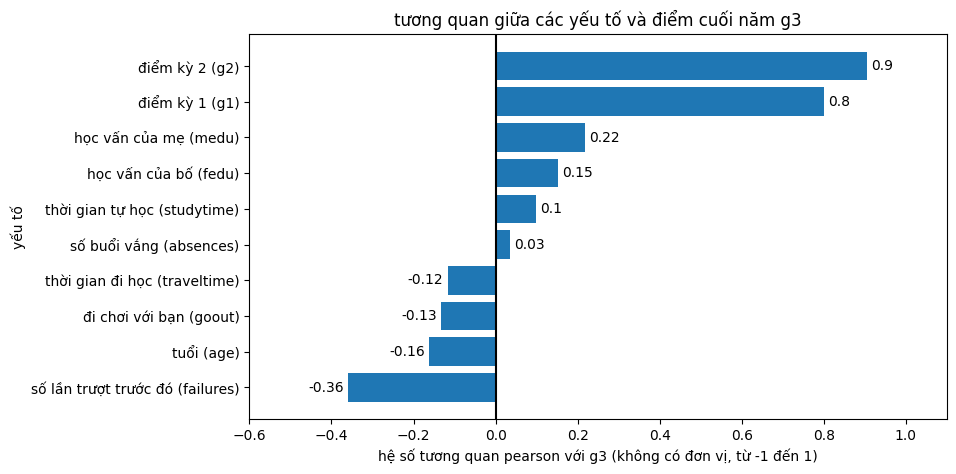

diễn giải biểu đồ 3: yếu tố liên quan mạnh nhất tới điểm cuối là điểm kỳ 2 (g2) với hệ số 0.9
thời gian tự học có hệ số 0.1 và số buổi vắng có hệ số 0.03 nên liên quan yếu hơn nhiều


In [ ]:
# biểu đồ 3: mức liên quan của từng yếu tố với điểm cuối (câu hỏi 2)
ten_bien = {
    'g1': 'điểm kỳ 1 (g1)', 'g2': 'điểm kỳ 2 (g2)', 'failures': 'số lần trượt trước đó (failures)',
    'studytime': 'thời gian tự học (studytime)', 'absences': 'số buổi vắng (absences)',
    'medu': 'học vấn của mẹ (medu)', 'fedu': 'học vấn của bố (fedu)', 'age': 'tuổi (age)',
    'goout': 'đi chơi với bạn (goout)', 'traveltime': 'thời gian đi học (traveltime)'
}
gia_tri = tuong_quan[list(ten_bien.keys())].sort_values()
plt.figure(figsize=(9, 5))
plt.barh([ten_bien[k] for k in gia_tri.index], gia_tri.values)
plt.axvline(0, color='black')
for i, v in enumerate(gia_tri.values):
    if v >= 0:
        plt.text(v + 0.01, i, round(v, 2), va='center', ha='left')
    else:
        plt.text(v - 0.01, i, round(v, 2), va='center', ha='right')
plt.xlim(-0.6, 1.1)
plt.title('tương quan giữa các yếu tố và điểm cuối năm g3')
plt.xlabel('hệ số tương quan pearson với g3 (không có đơn vị, từ -1 đến 1)')
plt.ylabel('yếu tố')
plt.savefig('hinh3.png', dpi=150, bbox_inches='tight')
plt.show()

print('diễn giải biểu đồ 3: yếu tố liên quan mạnh nhất tới điểm cuối là', ten_bien[gia_tri.abs().idxmax()],
      'với hệ số', round(gia_tri[gia_tri.abs().idxmax()], 2))
print('thời gian tự học có hệ số', round(tuong_quan['studytime'], 2),
      'và số buổi vắng có hệ số', round(tuong_quan['absences'], 2), 'nên liên quan yếu hơn nhiều')

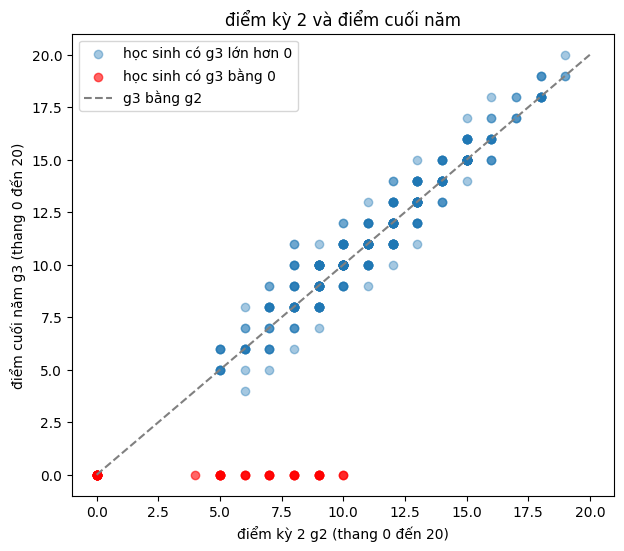

diễn giải biểu đồ 4: học sinh điểm kỳ 2 cao thì thường cao ở cuối năm, hệ số tương quan 0.9
có 25 học sinh còn điểm kỳ 2 lớn hơn 0 nhưng cuối năm bị 0 điểm, nằm sát trục ngang phía dưới đường chéo


In [ ]:
# biểu đồ 4: điểm kỳ 2 và điểm cuối năm (câu hỏi 2 và 3)
nhom_0 = df[df['g3'] == 0]
nhom_khac = df[df['g3'] > 0]
plt.figure(figsize=(7, 6))
plt.scatter(nhom_khac['g2'], nhom_khac['g3'], alpha=0.4, label='học sinh có g3 lớn hơn 0')
plt.scatter(nhom_0['g2'], nhom_0['g3'], alpha=0.6, color='red', label='học sinh có g3 bằng 0')
plt.plot([0, 20], [0, 20], linestyle='--', color='gray', label='g3 bằng g2')
plt.title('điểm kỳ 2 và điểm cuối năm')
plt.xlabel('điểm kỳ 2 g2 (thang 0 đến 20)')
plt.ylabel('điểm cuối năm g3 (thang 0 đến 20)')
plt.legend()
plt.savefig('hinh4.png', dpi=150, bbox_inches='tight')
plt.show()

roi_bo = ((df['g3'] == 0) & (df['g2'] > 0)).sum()
print('diễn giải biểu đồ 4: học sinh điểm kỳ 2 cao thì thường cao ở cuối năm, hệ số tương quan', round(df['g2'].corr(df['g3']), 2))
print('có', roi_bo, 'học sinh còn điểm kỳ 2 lớn hơn 0 nhưng cuối năm bị 0 điểm, nằm sát trục ngang phía dưới đường chéo')

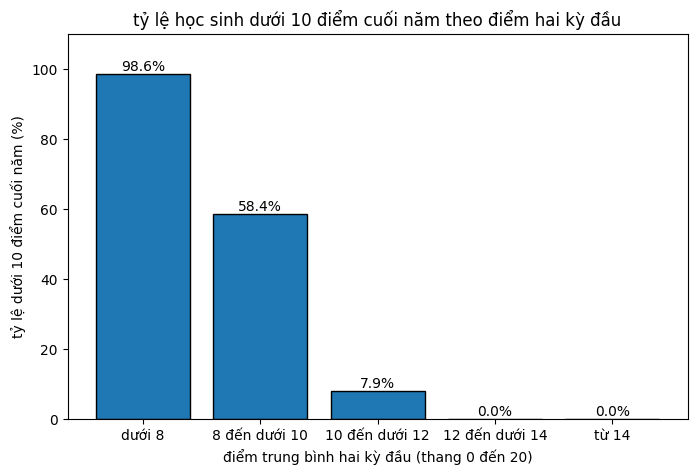

diễn giải biểu đồ 5: điểm hai kỳ đầu càng thấp thì tỷ lệ cuối năm dưới 10 càng cao
nhom_giua_ky
dưới 8            98.6
8 đến dưới 10     58.4
10 đến dưới 12     7.9
12 đến dưới 14     0.0
từ 14              0.0
Name: nguy_co, dtype: float64


In [ ]:
# biểu đồ 5: tỷ lệ dưới 10 điểm cuối năm theo nhóm điểm hai kỳ đầu (câu hỏi 3)
moc = [0, 8, 10, 12, 14, 20.1]
nhan_nhom = ['dưới 8', '8 đến dưới 10', '10 đến dưới 12', '12 đến dưới 14', 'từ 14']
df['nhom_giua_ky'] = pd.cut(df['tb_giua_ky'], bins=moc, labels=nhan_nhom, right=False)
ti_le = df.groupby('nhom_giua_ky', observed=False)['nguy_co'].mean() * 100

plt.figure(figsize=(8, 5))
plt.bar(nhan_nhom, ti_le.values, edgecolor='black')
for i, v in enumerate(ti_le.values):
    plt.text(i, v + 1, str(round(v, 1)) + '%', ha='center')
plt.title('tỷ lệ học sinh dưới 10 điểm cuối năm theo điểm hai kỳ đầu')
plt.xlabel('điểm trung bình hai kỳ đầu (thang 0 đến 20)')
plt.ylabel('tỷ lệ dưới 10 điểm cuối năm (%)')
plt.ylim(0, 110)
plt.savefig('hinh5.png', dpi=150, bbox_inches='tight')
plt.show()

print('diễn giải biểu đồ 5: điểm hai kỳ đầu càng thấp thì tỷ lệ cuối năm dưới 10 càng cao')
print(ti_le.round(1))

In [ ]:
# nhận biết nhóm nguy cơ từ dữ liệu giữa kỳ (câu hỏi 3)
# quy tắc đơn giản (không dùng mô hình học máy): điểm trung bình hai kỳ đầu dưới 10 thì gắn cờ
df['bao_dong'] = (df['tb_giua_ky'] < 10).astype(int)

tp = ((df['bao_dong'] == 1) & (df['nguy_co'] == 1)).sum()
fp = ((df['bao_dong'] == 1) & (df['nguy_co'] == 0)).sum()
fn = ((df['bao_dong'] == 0) & (df['nguy_co'] == 1)).sum()
tn = ((df['bao_dong'] == 0) & (df['nguy_co'] == 0)).sum()
print('bảng kết quả: gắn cờ đúng', tp, ', gắn cờ nhầm', fp, ', bỏ sót', fn, ', không gắn cờ và đúng', tn)

do_chinh_xac = tp / max(tp + fp, 1)
do_phu = tp / max(tp + fn, 1)
print('độ chính xác:', round(do_chinh_xac, 2), '- độ phủ:', round(do_phu, 2))

bảng kết quả: gắn cờ đúng 124 , gắn cờ nhầm 38 , bỏ sót 6 , không gắn cờ và đúng 227
độ chính xác: 0.77 - độ phủ: 0.95


In [ ]:
# ba nhận định có căn cứ và giới hạn của từng nhận định
r_g1 = df['g1'].corr(df['g3'])
r_g2 = df['g2'].corr(df['g3'])
r_f = df['failures'].corr(df['g3'])
r_s = df['studytime'].corr(df['g3'])
r_a = df['absences'].corr(df['g3'])

print('nhận định 1 (câu hỏi 1): điểm g3 trung bình', round(df['g3'].mean(), 2), ', trung vị', df['g3'].median(),
      ', có', so_0, 'học sinh bị 0 điểm tách riêng khỏi phần còn lại')
print('giới hạn 1: dữ liệu không cho biết vì sao các em bị 0 điểm (bỏ thi, nghỉ học hay lý do khác), chỉ có môn toán ở hai trường tại Bồ Đào Nha nên không suy rộng cho sinh viên đại học hay môn khác')
print()
print('nhận định 2 (câu hỏi 2): hệ số tương quan với g3 của g2 là', round(r_g2, 2), ', của g1 là', round(r_g1, 2),
      ', của failures là', round(r_f, 2), ', của studytime là', round(r_s, 2), ', của absences là', round(r_a, 2))
print('giới hạn 2: tương quan không chứng minh nguyên nhân, g2 sát g3 về thời gian nên mạnh là điều dễ hiểu và không có nghĩa nâng g2 sẽ tự nâng g3; số buổi vắng yếu có thể một phần do nhóm 0 điểm (xem hai hệ số absences ở trên)')
print()
print('nhận định 3 (câu hỏi 3): quy tắc điểm trung bình hai kỳ đầu dưới 10 gắn cờ', df['bao_dong'].sum(), 'học sinh, bắt được',
      tp, 'trong', df['nguy_co'].sum(), 'học sinh thật sự dưới 10 cuối năm (độ phủ', round(do_phu, 2), ', độ chính xác'
      , round(do_chinh_xac, 2), ')')
print('giới hạn 3: có', fp, 'em bị gắn cờ nhầm và', fn, 'em bị bỏ sót; hai kỳ đầu là điểm đã có chứ chưa phải dự báo sớm; quy tắc chỉ dựa vào điểm số và ngưỡng 10 là giả định của bài')

nhận định 1 (câu hỏi 1): điểm g3 trung bình 10.42 , trung vị 11.0 , có 38 học sinh bị 0 điểm tách riêng khỏi phần còn lại
giới hạn 1: dữ liệu không cho biết vì sao các em bị 0 điểm (bỏ thi, nghỉ học hay lý do khác), chỉ có môn toán ở hai trường tại Bồ Đào Nha nên không suy rộng cho sinh viên đại học hay môn khác

nhận định 2 (câu hỏi 2): hệ số tương quan với g3 của g2 là 0.9 , của g1 là 0.8 , của failures là -0.36 , của studytime là 0.1 , của absences là 0.03
giới hạn 2: tương quan không chứng minh nguyên nhân, g2 sát g3 về thời gian nên mạnh là điều dễ hiểu và không có nghĩa nâng g2 sẽ tự nâng g3; số buổi vắng yếu có thể một phần do nhóm 0 điểm (xem hai hệ số absences ở trên)

nhận định 3 (câu hỏi 3): quy tắc điểm trung bình hai kỳ đầu dưới 10 gắn cờ 162 học sinh, bắt được 124 trong 130 học sinh thật sự dưới 10 cuối năm (độ phủ 0.95 , độ chính xác 0.77 )
giới hạn 3: có 38 em bị gắn cờ nhầm và 6 em bị bỏ sót; hai kỳ đầu là điểm đã có chứ chưa phải dự báo sớm; quy tắc chỉ dựa vào điểm s

In [ ]:
# kiểm tra công bằng: nhóm nào bị gắn cờ nhiều hơn theo các biến có thể đại diện gián tiếp cho hoàn cảnh kinh tế gia đình
bien_dai_dien = ['internet', 'paid', 'address', 'medu', 'fedu', 'mjob', 'fjob']
for cot in bien_dai_dien:
    bang = df.groupby(cot).agg(so_hs=('g3', 'size'), g3_tb=('g3', 'mean'), ti_le_gan_co=('bao_dong', 'mean'))
    print(bang.round(2))

print('đọc các bảng trên: nếu tỷ lệ gắn cờ giữa các nhóm khác nhau rõ thì quy tắc có thể bất lợi cho nhóm đó, nhóm nhỏ (so_hs ít) thì số liệu không đáng tin')

          so_hs  g3_tb  ti_le_gan_co
internet                            
no           66   9.41          0.53
yes         329  10.62          0.39
      so_hs  g3_tb  ti_le_gan_co
paid                            
no      214   9.99          0.43
yes     181  10.92          0.39
         so_hs  g3_tb  ti_le_gan_co
address                            
R           88   9.51          0.50
U          307  10.67          0.38
      so_hs  g3_tb  ti_le_gan_co
medu                            
0         3  13.00          0.33
1        59   8.68          0.61
2       103   9.73          0.43
3        99  10.30          0.44
4       131  11.76          0.28
      so_hs  g3_tb  ti_le_gan_co
fedu                            
0         2  13.00          0.00
1        82   9.16          0.61
2       115  10.26          0.38
3       100  10.66          0.41
4        96  11.36          0.28
          so_hs  g3_tb  ti_le_gan_co
mjob                                
at_home      59   9.15          0.51
hea

In [ ]:
# thảo luận đạo đức (bắt buộc)

# 1. nếu nhà trường dùng kết quả này để dán nhãn sinh viên thì rủi ro gì?
# nhãn nguy cơ cao gắn lên hồ sơ làm giảng viên, bạn bè và chính em đó nhìn em theo hướng thấp kém, trong khi quy tắc vẫn gắn cờ nhầm một số em (xem số gắn cờ nhầm ở trên)
# danh sách bị lộ hoặc dùng sai mục đích (xét học bổng, kỷ luật) xâm phạm quyền riêng tư
# quy tắc dựa trên điểm quá khứ nên bất lợi cho em chỉ gặp khó khăn tạm thời

# 2. có nguy cơ tạo lời tiên tri tự ứng nghiệm không? có
# khi em bị coi là sắp trượt, người xung quanh kỳ vọng thấp hơn, em mất động lực, và kết quả xấu đi đúng như dự đoán dù nguyên nhân là chính cái nhãn
# cách giảm: chỉ dùng để mời hỗ trợ (phụ đạo, tư vấn), không ghi vào học bạ, giữ kín danh sách, có người xem xét từng trường hợp và đánh giá lại định kỳ

# 3. biến nào có thể đại diện gián tiếp cho hoàn cảnh kinh tế gia đình?
# internet (có internet ở nhà), paid (học thêm có trả phí), medu và fedu (học vấn của mẹ và bố), mjob và fjob (nghề của mẹ và bố), address (thành thị hay nông thôn)
# bộ dữ liệu không có cột thu nhập nên đây chỉ là suy đoán gián tiếp
# nếu dùng các biến này để gắn cờ thì sẽ phạt em vì hoàn cảnh gia đình chứ không phải vì việc học
# vì vậy bài này chỉ dùng điểm số để gắn cờ, còn các biến trên chỉ dùng để kiểm tra công bằng như ở trên

print('đã chạy xong toàn bộ notebook')

đã chạy xong toàn bộ notebook
